# Defining PBO from out-of-sample ranks

This native Julia companion preserves the original S&P 500 observations, thirty-two trial rules, symmetric partitions, population-standard-deviation scores and rank-logit decision. Saved public random innovations and moving-block bootstrap row positions reproduce the original seeded experiments; all simulated returns, scores, ranks and PBO estimates are calculated in Julia. Selected configuration indices are one-based except for the explicitly preserved zero-based preliminary example labels. Timing measurements describe this native execution. Figures use the requested dark theme, and outputs are saved under `outputs/julia`.

Each symmetric split selects the trial with the largest in-sample performance:

$$
n_c^\star=\arg\max_{1\leq n\leq N}R_{c,n}^{\mathrm{IS}}.
$$

Here, $c$ identifies a symmetric split, $R_{c,n}^{\mathrm{IS}}$ is the in-sample performance of trial $n$, $N$ is the number of trials, and $n_c^\star$ is the trial selected within split $c$.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("19_backtest_overfitting");
using CSV, TOML, Printf, Combinatorics
using RiskLabAI.Backtest: probability_of_backtest_overfitting
using RiskLabAI.Validation: bagged_probability_of_backtest_overfitting,adaptive_probability_of_backtest_overfitting
prefix = "rank"
source_path = dataset_path("fred_sp500")
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
returns = vcat(NaN,diff(log.(prices)))

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    result[1:span-1] .= NaN
    return result
end

columns,catalog_records = Vector{Float64}[],NamedTuple[]
for fast in [3,5,10,20], slow in [30,60,120,240]
    fast_average,slow_average = exponential_average(prices,fast),exponential_average(prices,slow)
    signal = sign.(fast_average.-slow_average)
    for index in 2:length(signal)
        signal[index]==0 && (signal[index]=signal[index-1])
    end
    position = vcat(NaN,signal[1:end-1])
    for (orientation,multiplier) in [("Trend",1.),("Reversal",-1.)]
        name = orientation*" "*string(fast)*"/"*string(slow)
        push!(columns,multiplier.*position.*returns)
        push!(catalog_records,(trial=length(catalog_records)+1,rule=orientation,fast=fast,slow=slow,name=name))
    end
end
complete = findall(vec(all(isfinite,reduce(hcat,columns);dims=2)))
performances = reduce(hcat,columns)[complete,:]
dates = price_dates[complete]
strategy_catalog = DataFrame(catalog_records)
rename!(strategy_catalog,["Trial","Rule","Fast span","Slow span","Name"])
names_trials = strategy_catalog.Name
@assert size(performances)==(2090,32)
performance_frame = DataFrame(performances,names_trials)
insertcols!(performance_frame,1,:date=>dates)
save_data(performance_frame,paths,prefix*"_performances")
save_data(DataFrame(date=price_dates,price=prices),paths,prefix*"_prices")
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter19-"*replace(name,"_"=>"-"))

function read_primitive(name)
    root = joinpath("..","data","chapter19_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    metadata = TOML.parsefile(manifest_path)["files"][name*".csv"]
    path = joinpath(root,name*".csv")
    values = Matrix(CSV.read(path,DataFrame))
    @assert size(values)==(metadata[],metadata["columns"])
    return values
end

function time_groups(count,partitions)
    base,remaining = divrem(count,partitions)
    boundaries = cumsum(vcat(0,[base+(index<=remaining) for index in 1:partitions]))
    return [collect(boundaries[index]+1:boundaries[index+1]) for index in 1:partitions]
end

function score_vector(values)
    deviations,means = vec(std(values;dims=1,corrected=false)),vec(mean(values;dims=1))
    return [deviation>0 ? average/deviation : 0. for (average,deviation) in zip(means,deviations)]
end

function cscv_records(values,partitions;names=["Trial "*string(index) for index in axes(values,2)],key=nothing)
    groups = time_groups(size(values,1),partitions)
    records = NamedTuple[]
    for (number,train_groups) in enumerate(combinations(1:partitions,partitions÷2))
        test_groups = setdiff(1:partitions,train_groups)
        train,test = reduce(vcat,groups[train_groups]),reduce(vcat,groups[test_groups])
        training_scores,testing_scores = score_vector(values[train,:]),score_vector(values[test,:])
        selected = argmax(training_scores)
        ranks = invperm(sortperm(testing_scores))
        rank = ranks[selected]
        relative = rank/(size(values,2)+1)
        logit = log(relative/(1-relative))
        push!(records,(combination=number,train=join(train_groups,", "),test=join(test_groups,", "),n_train=length(train),n_test=length(test),selected=selected,name=names[selected],in_sample=training_scores[selected],out_sample=testing_scores[selected],rank=rank,relative=relative,logit=logit,overfit=Int(logit<=0)))
    end
    result = DataFrame(records)
    rename!(result,["Combination","Training groups","Testing groups","Training observations","Testing observations","Selected trial","Selected name","In-sample score","Out-of-sample score","Out-of-sample rank","Relative rank","Logit","Overfit"])
    key===nothing || save_data(result,paths,key*"_records")
    return result
end

function manual_pbo(values,partitions)
    records = cscv_records(values,partitions)
    return mean(records.Overfit),records.Logit
end

function histogram_panel(values,bins,color,key;density=false,title_text="")
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    edges[end] = nextfloat(edges[end])
    counts = zeros(Int,bins)
    for value in values
        counts[searchsortedlast(edges,value)] += 1
    end
    widths = diff(edges)
    heights = density ? counts./sum(counts)./widths : Float64.(counts)
    @assert sum(counts)==length(values)
    save_data(DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts,height=heights),paths,key*"_histogram")
    panel = bar((edges[1:end-1].+edges[2:end])./2,heights;bar_width=widths,color,fillalpha=.9,linecolor=palette.background,label="",xlabel="Logit",ylabel=density ? "Density" : "Combinations",title=title_text)
    vline!(panel,[0.];color=palette.rose,label="",linewidth=1.5)
    return panel
end

function average_ranks(values)
    order = sortperm(values)
    ranks = zeros(length(values))
    first_position = 1
    while first_position<=length(values)
        last_position = first_position
        while last_position<length(values) && values[order[last_position+1]]==values[order[first_position]]
            last_position += 1
        end
        ranks[order[first_position:last_position]] .= (first_position+last_position)/2
        first_position = last_position+1
    end
    return ranks
end


average_ranks (generic function with 1 method)

## Transforming relative rank into a logit

The selected trial's out-of-sample rank is placed inside the unit interval and then mapped to log odds:

$$
\overline\omega_c=\frac{r_{c,n_c^\star}^{\mathrm{OOS}}}{N+1},
\qquad
\lambda_c=\log\!\left(\frac{\overline\omega_c}{1-\overline\omega_c}\right).
$$

Here, $r_{c,n_c^\star}^{\mathrm{OOS}}$ is the ascending out-of-sample rank of the trial selected in-sample, $N+1$ keeps the relative rank strictly between zero and one, $\overline\omega_c$ is the relative rank, and $\lambda_c$ is its logit. A nonpositive logit places the selected trial in the lower half of the out-of-sample ranking.

Row,Quantity,Value
,String,Float64
1,Observations,2090.0
2,Trials,32.0
3,Time groups,8.0
4,Symmetric combinations,70.0
5,Released PBO,0.471429
6,Explicit PBO,0.471429
7,Mean logit,-0.111416
8,Median logit,0.0606246
9,Out-of-sample loss share,0.471429


Row,Quantile,Logit,Relative rank
,Float64,Float64,Float64
1,0.0,-3.46574,0.030303
2,0.05,-3.46574,0.030303
3,0.25,-0.943849,0.280303
4,0.5,0.0606246,0.515152
5,0.75,0.980829,0.727273
6,0.95,1.981,0.878788
7,1.0,3.46574,0.969697


Row,Combination,Selected name,In-sample score,Out-of-sample score,Out-of-sample rank,Relative rank,Logit,Overfit
,Int64,String,Float64,Float64,Int64,Float64,Float64,Int64
1,1,Trend 10/120,0.0396254,0.00241265,18,0.545455,0.182322,0
2,2,Trend 5/30,0.0254584,0.034319,20,0.606061,0.430783,0
3,3,Trend 3/30,0.032784,0.0119994,18,0.545455,0.182322,0
4,4,Trend 20/60,0.0419338,0.00788078,25,0.757576,1.13943,0
5,5,Trend 3/30,0.0383717,0.00367479,17,0.515152,0.0606246,0
6,6,Trend 20/240,0.0165133,-0.0112493,14,0.424242,-0.305382,1
7,7,Trend 20/240,0.0358682,-0.0200218,11,0.333333,-0.693147,1
8,8,Trend 20/240,0.0706422,-0.0393814,1,0.030303,-3.46574,1
9,9,Trend 10/120,0.0378959,0.0125174,24,0.727273,0.980829,0


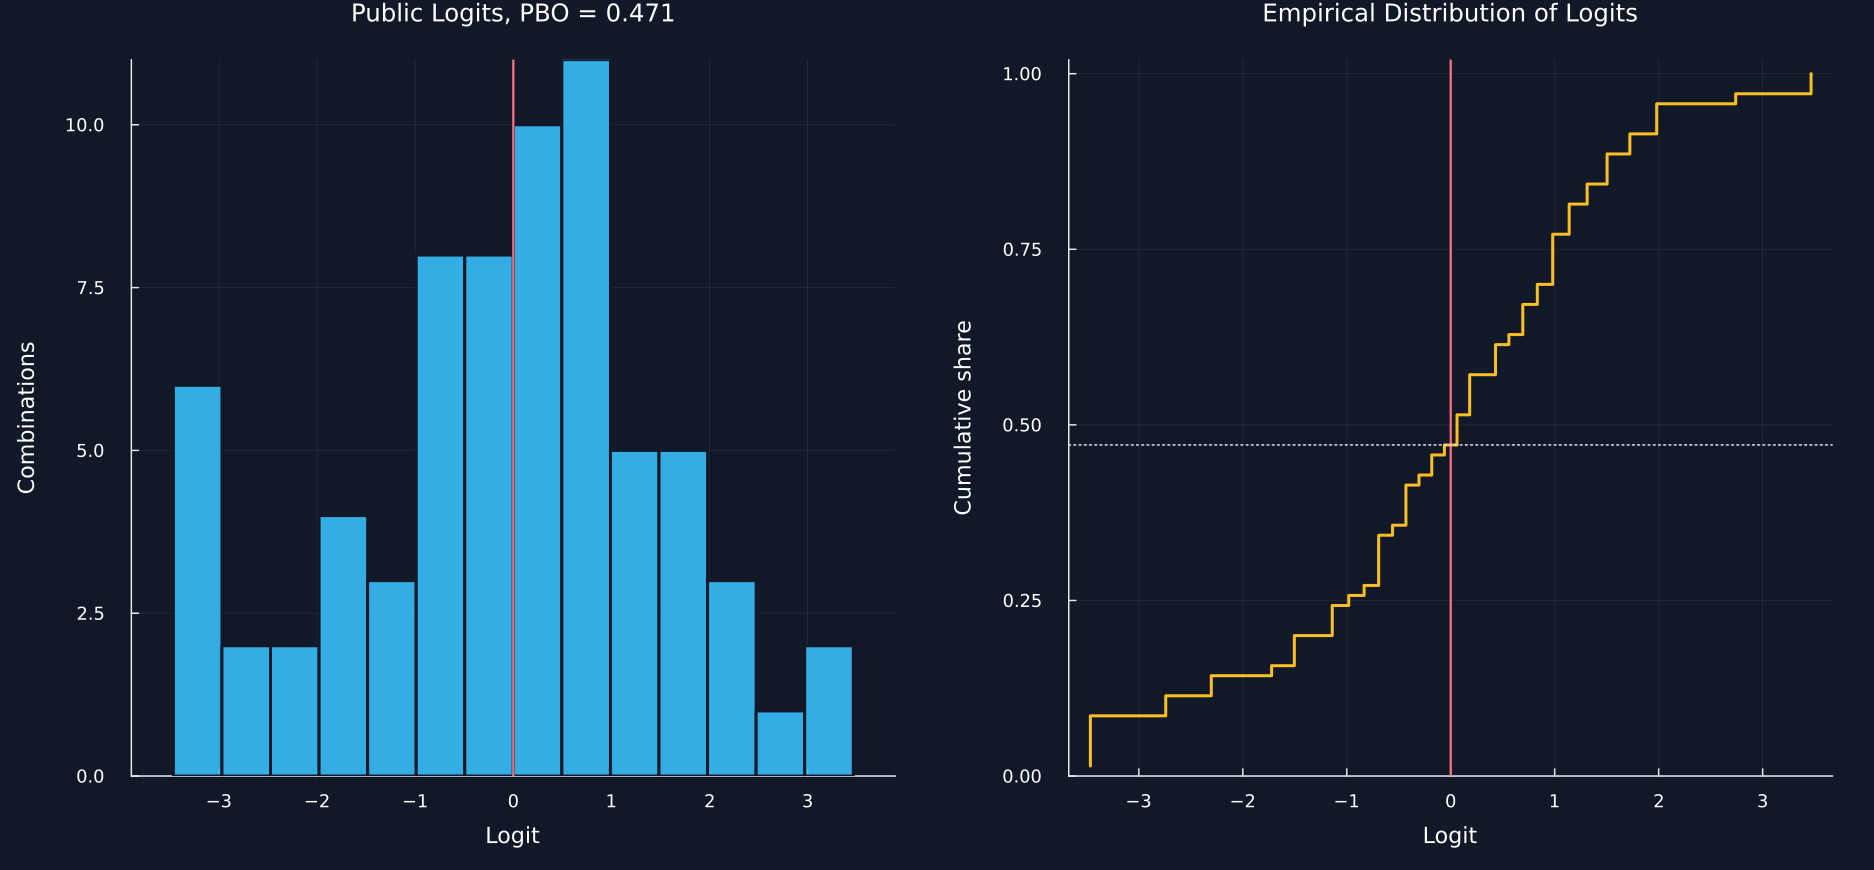

In [2]:
public_records = cscv_records(performances,8;names=names_trials,key="rank_public")
released_pbo,released_logits = probability_of_backtest_overfitting(performances;n_partitions=8)
manual_value = mean(public_records.Overfit)
public_summary = DataFrame("Quantity"=>["Observations","Trials","Time groups","Symmetric combinations","Released PBO","Explicit PBO","Mean logit","Median logit","Out-of-sample loss share"],"Value"=>[size(performances,1),32,8,70,released_pbo,manual_value,mean(public_records.Logit),median(public_records.Logit),mean(public_records[!,"Out-of-sample score"].<0)])
quantile_levels = [0.,.05,.25,.5,.75,.95,1.]
logit_quantiles = DataFrame("Quantile"=>quantile_levels,"Logit"=>quantile(public_records.Logit,quantile_levels),"Relative rank"=>quantile(public_records[!,"Relative rank"],quantile_levels))
split_examples = select(first(public_records,14),["Combination","Selected name","In-sample score","Out-of-sample score","Out-of-sample rank","Relative rank","Logit","Overfit"])
table(public_summary,"public_pbo_summary","PBO summary for the public strategy family.")
table(logit_quantiles,"public_logit_quantiles","Quantiles of public relative ranks and logits.")
table(split_examples,"public_split_examples","The first fourteen selected-trial outcomes.")
save_data(DataFrame(combination=collect(1:70),logit=released_logits),paths,"released_public_logits")
p1 = histogram_panel(public_records.Logit,14,palette.cyan,"public_logit";title_text=@sprintf("Public Logits, PBO = %.3f",released_pbo))
ordered_logits = sort(public_records.Logit)
cumulative = collect(1:70)./70
save_data(DataFrame(logit=ordered_logits,cumulative=cumulative),paths,"public_logit_ecdf")
p2 = plot(ordered_logits,cumulative;seriestype=:steppost,color=palette.amber,label="",xlabel="Logit",ylabel="Cumulative share",title="Empirical Distribution of Logits",ylims=(0,1.02))
vline!(p2,[0.];color=palette.rose,label="",linewidth=1.5)
hline!(p2,[released_pbo];color=palette.text,linestyle=:dot,label="",linewidth=1)
save_figure(plot(p1,p2;layout=(1,2),size=(1250,580),left_margin=7Plots.mm,bottom_margin=7Plots.mm),paths,"public_logit_distribution")


The empirical probability of backtest overfitting is the share of nonpositive logits:

$$
\widehat\phi
=\frac{1}{C_S}\sum_{c=1}^{C_S}\one\{\lambda_c\leq0\}.
$$

Here, $\widehat\phi$ is the PBO estimate, $C_S$ is the number of symmetric combinations, $\lambda_c$ is the logit for combination $c$, and $\one\{\lambda_c\leq0\}$ equals one when the selected trial ranks in the lower out-of-sample half and zero otherwise.

## Performance Degradation

A straight-line summary relates the selected trial's out-of-sample score to its in-sample score:

$$
R_c^{\mathrm{OOS}}=\alpha+\beta R_c^{\mathrm{IS}}+\varepsilon_c.
$$

Here, $R_c^{\mathrm{IS}}$ and $R_c^{\mathrm{OOS}}$ are the selected trial's two scores in split $c$, $\alpha$ is the fitted intercept, $\beta$ is the fitted slope, and $\varepsilon_c$ is the part not explained by the straight line. This descriptive slope does not establish causation.

Row,Selected trial,Selected name,Selections,Mean out-of-sample score,Overfit share,Selection share
,Int64,String,Int64,Float64,Float64,Float64
1,9,Trend 5/30,15,0.0274648,0.0,0.214286
2,27,Trend 20/60,12,0.00499891,0.333333,0.171429
3,1,Trend 3/30,11,0.00827707,0.181818,0.157143
4,31,Trend 20/240,8,-0.0242735,1.0,0.114286
5,21,Trend 10/120,5,0.00200462,0.4,0.0714286
6,15,Trend 5/240,4,-0.0233008,1.0,0.0571429
7,30,Reversal 20/120,4,-0.046633,1.0,0.0571429
8,13,Trend 5/120,3,0.0051801,0.333333,0.0428571
9,23,Trend 10/240,3,-0.0189738,1.0,0.0428571


Row,Quantity,Value
,String,Float64
1,Intercept,0.0352063
2,Slope,-0.962999
3,Score correlation,-0.478701
4,Out-of-sample loss share,0.471429
5,Distinct selected trials,12.0


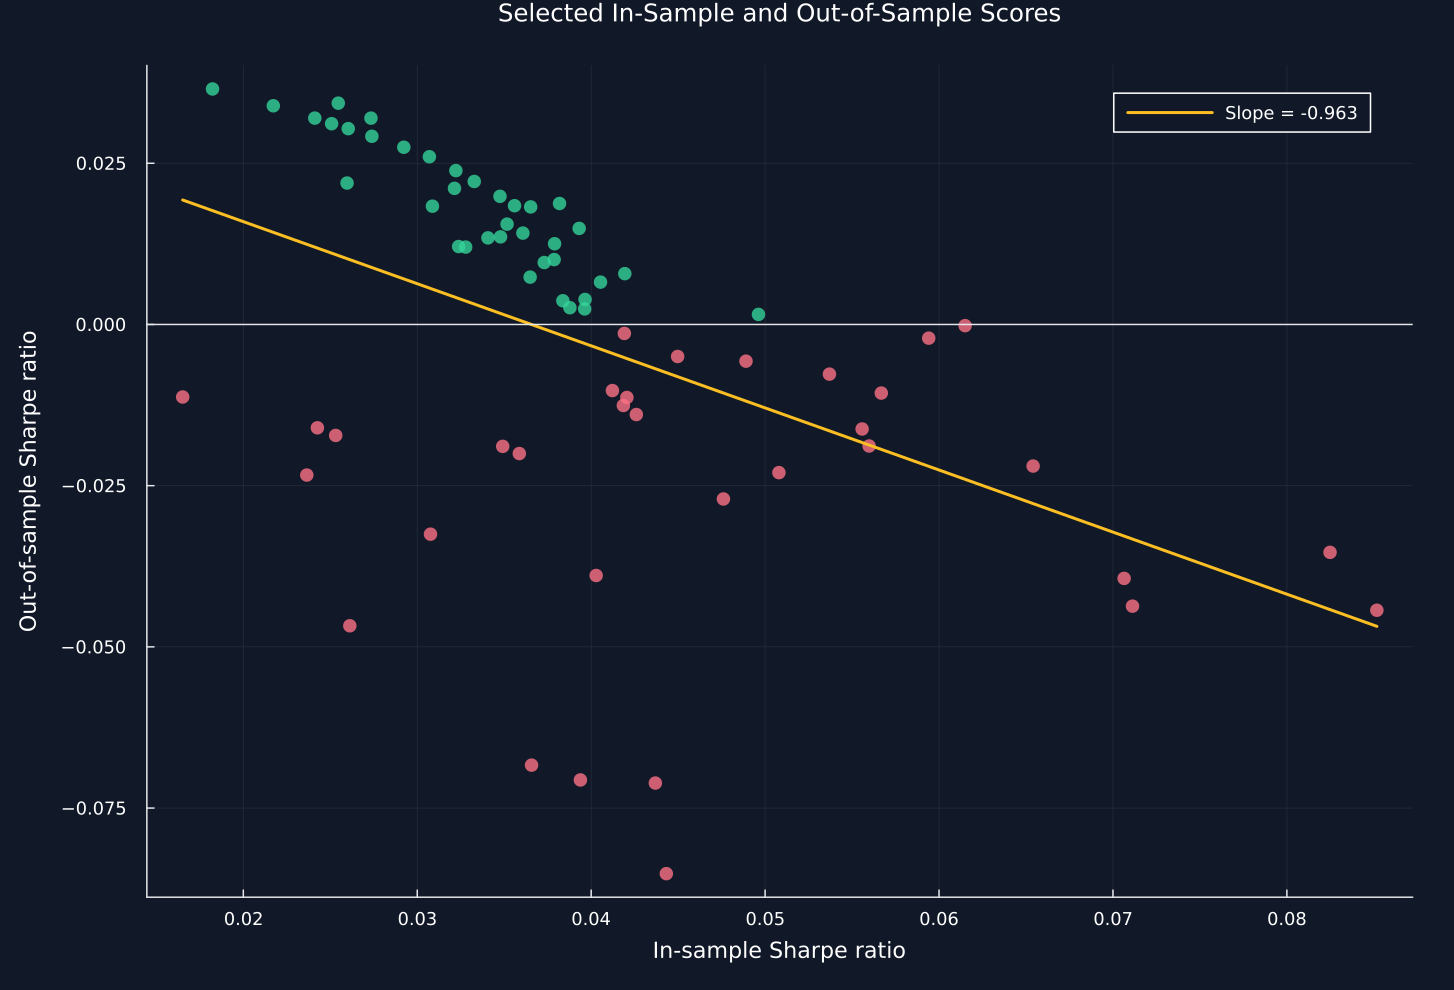

In [3]:
inside,outside = public_records[!,"In-sample score"],public_records[!,"Out-of-sample score"]
intercept,slope = hcat(ones(70),inside)\outside
correlation = cor(inside,outside)
selection_frequency = combine(groupby(public_records,["Selected trial","Selected name"];sort=true),nrow=>"Selections","Out-of-sample score"=>mean=>"Mean out-of-sample score","Overfit"=>mean=>"Overfit share")
sort!(selection_frequency,["Selections","Selected trial"];rev=[true,false])
selection_frequency[!,"Selection share"] = selection_frequency.Selections./70
degradation_summary = DataFrame("Quantity"=>["Intercept","Slope","Score correlation","Out-of-sample loss share","Distinct selected trials"],"Value"=>[intercept,slope,correlation,mean(outside.<0),nrow(selection_frequency)])
table(selection_frequency,"public_selection_frequency","Selection frequencies across public symmetric splits.")
table(degradation_summary,"performance_degradation_summary","Descriptive relation between selected in-sample and out-of-sample scores.")
grid = collect(range(minimum(inside),maximum(inside);length=100))
save_data(DataFrame(in_sample=grid,fitted=intercept.+slope.*grid),paths,"performance_degradation_line")
figure = scatter(inside,outside;color=ifelse.(public_records.Overfit.==1,palette.rose,palette.green),markerstrokewidth=0,alpha=.8,markersize=5,label="",xlabel="In-sample Sharpe ratio",ylabel="Out-of-sample Sharpe ratio",title="Selected In-Sample and Out-of-Sample Scores",size=(970,660),legend=:topright)
plot!(figure,grid,intercept.+slope.*grid;color=palette.amber,label=@sprintf("Slope = %.3f",slope))
hline!(figure,[0.];color=palette.text,label="",linewidth=1)
save_figure(figure,paths,"public_performance_degradation")


## Preliminary Null Experiments

If the overfit indicators were independent Bernoulli observations, a useful scale for the sampling error of their mean would be:

$$
\operatorname{SE}(\widehat\phi)\approx\sqrt{\frac{\widehat\phi(1-\widehat\phi)}{C_S}}.
$$

Here, $\operatorname{SE}(\widehat\phi)$ is the approximate standard error, $\widehat\phi$ is the observed PBO, and $C_S$ is the number of logits. The symmetric combinations share observations, so this expression is a scale calculation rather than an exact independent-sample uncertainty statement.

Row,Experiment,Observations,Trials,Time groups,Logits,PBO,Approximate standard error
,String,Int64,Int64,Int64,Int64,Float64,Float64
1,"Seed 1, standard normal",1000,50,10,252,0.654762,0.0299503
2,"Seed 42, small common drift",1000,50,16,12870,0.544678,0.00438975


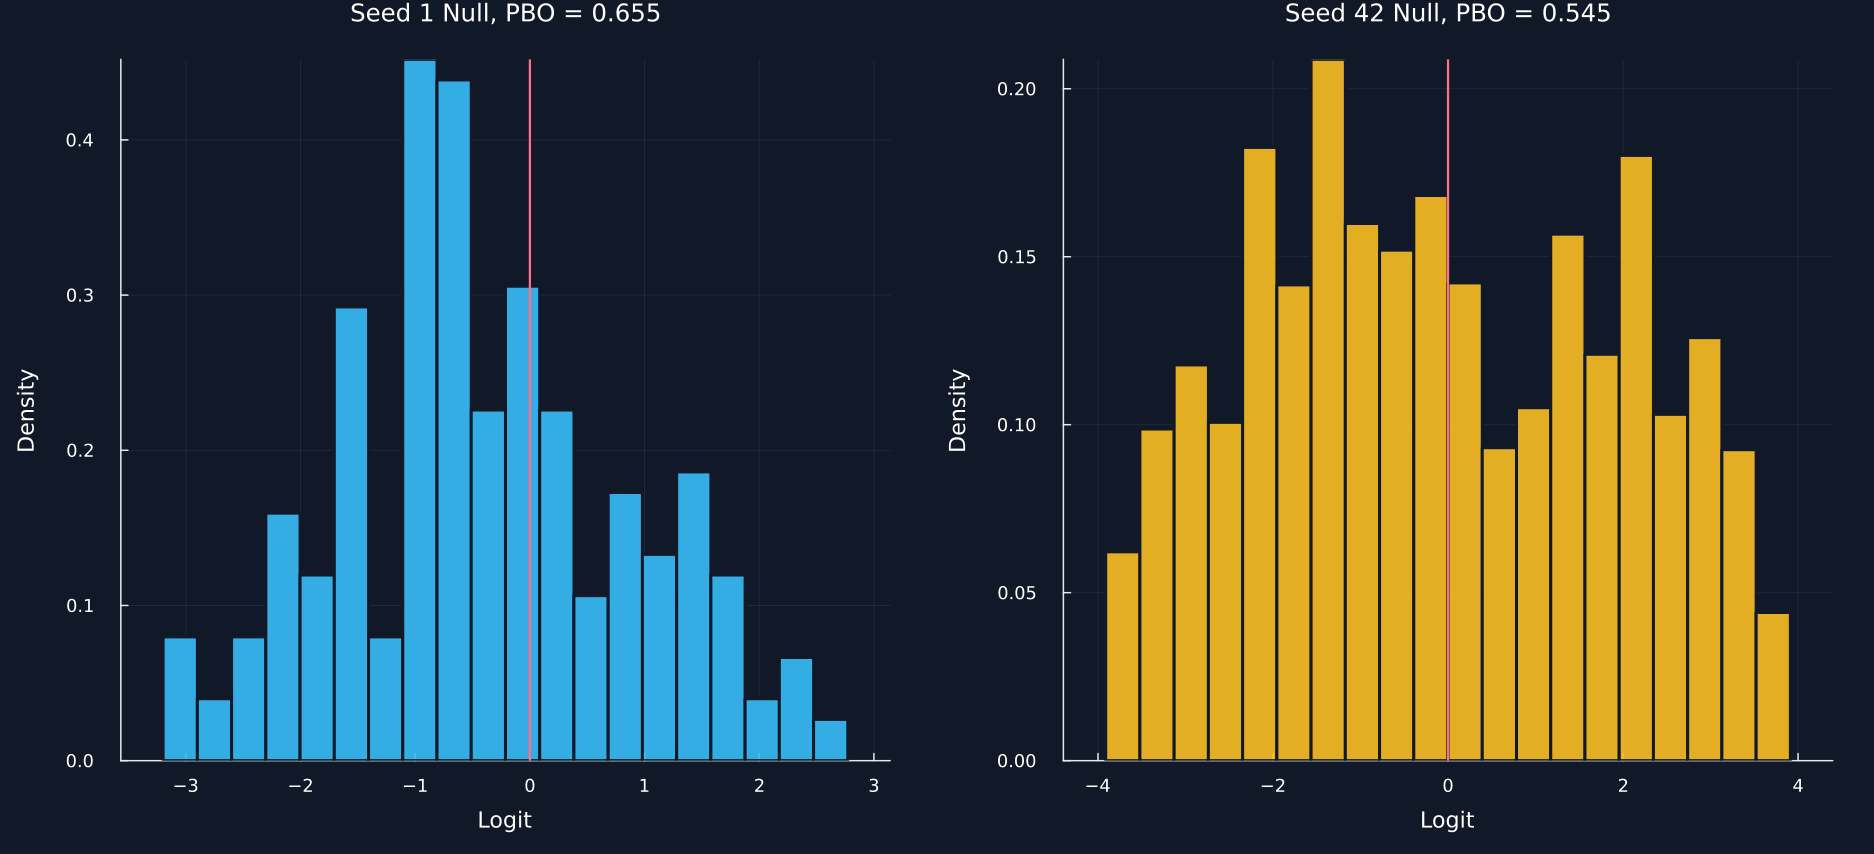

In [4]:
first_null = read_primitive("null_one")
second_null = read_primitive("null_two") .* 0.01 .+ 0.0001
first_pbo,first_logits = probability_of_backtest_overfitting(first_null;n_partitions=10)
second_pbo,second_logits = probability_of_backtest_overfitting(second_null;n_partitions=16)
preliminary_reproduction = DataFrame("Experiment"=>["Seed 1, standard normal","Seed 42, small common drift"],"Observations"=>[1000,1000],"Trials"=>[50,50],"Time groups"=>[10,16],"Logits"=>length.([first_logits,second_logits]),"PBO"=>[first_pbo,second_pbo],"Approximate standard error"=>[sqrt(value*(1-value)/length(logits)) for (value,logits) in [(first_pbo,first_logits),(second_pbo,second_logits)]])
table(preliminary_reproduction,"preliminary_null_reproduction","Reproduction of the two preliminary no-skill PBO experiments.")
save_data(DataFrame(logit=first_logits),paths,"first_null_logits")
save_data(DataFrame(logit=second_logits),paths,"second_null_logits")
p1 = histogram_panel(first_logits,20,palette.cyan,"first_null";density=true,title_text=@sprintf("Seed 1 Null, PBO = %.3f",first_pbo))
p2 = histogram_panel(second_logits,20,palette.amber,"second_null";density=true,title_text=@sprintf("Seed 42 Null, PBO = %.3f",second_pbo))
save_figure(plot(p1,p2;layout=(1,2),size=(1250,570),left_margin=7Plots.mm,bottom_margin=7Plots.mm),paths,"preliminary_null_logits")


## Tests

In [5]:
@assert nrow(public_records)==70
@assert length(released_logits)==70
@assert released_pbo≈manual_value
@assert released_logits≈public_records.Logit
@assert all(value->0<value<1,public_records[!,"Relative rank"])
@assert all(value->value in [0,1],public_records.Overfit)
@assert sum(selection_frequency[!,"Selection share"])≈1
@assert sum(selection_frequency.Selections)==70
@assert round(first_pbo;digits=3)==.655
@assert round(second_pbo;digits=4)==.5447
@assert length(first_logits)==binomial(10,5)==252
@assert length(second_logits)==binomial(16,8)==12870
@assert isfile(joinpath(paths.figures,"public_logit_distribution.pdf"))
@assert isfile(joinpath(paths.figures,"public_performance_degradation.pdf"))
@assert isfile(joinpath(paths.figures,"preliminary_null_logits.pdf"))
@assert isfile(joinpath(paths.tables,"public_pbo_summary.tex"))
@assert isfile(joinpath(paths.tables,"public_logit_quantiles.tex"))
@assert isfile(joinpath(paths.tables,"public_split_examples.tex"))
@assert isfile(joinpath(paths.tables,"public_selection_frequency.tex"))
@assert isfile(joinpath(paths.tables,"performance_degradation_summary.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_null_reproduction.tex"))
